# $2 \times 2$ Ablation Study: Stage-1 Architecture ($\text{RoPE} + S^3\text{ Sparse}$) $\times$ Stage-2 Policy Optimization ($\text{Dr. GRPO}$)

This notebook evaluates all four checkpoints from the $2 \times 2$ factorial ablation design (`eval/eval_ablation_2x2.py`):
1. **Vanilla DINOv1 (`vit_small`)** — `cp/checkpoints_default_2/checkpoint0190.pth`
2. **RoPE + Sparse DINOv1 (`vit_small_sparse_rope`)** — `cp/checkpoints_rope_2/checkpoint0190.pth`
3. **Vanilla + Dr. GRPO** — `cp/checkpoints_def_grpo/checkpoint0190.pth`
4. **RoPE + Sparse + Dr. GRPO (Ours)** — `cp/checkpoints_rop_grpo/checkpoint0190.pth`

### Quantitative Benchmark Summary (CIFAR-10: 50,000 Train / 10,000 Test)

| Model Variant | Backbone Architecture | Stage-2 RLVR | $k$-NN Top-1 (%) | $k$-NN Top-5 (%) | Linear Probe Top-1 (%) | Foreground Mask IoU (%) | CorLoc @ IoU$\ge 0.5$ (%) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. Vanilla DINOv1** | `vit_small` | No | 71.13% | 96.57% | 78.07% | 58.88% | 79.93% |
| **2. RoPE + Sparse DINOv1** | `vit_small_sparse_rope` | No | 71.83% | 96.98% | 80.22% | 55.45% | 69.26% |
| **3. Vanilla + Dr. GRPO** | `vit_small` | **Dr. GRPO** | 71.29% | 96.73% | 78.44% | **78.98%** (+20.10%) | **99.91%** (+19.98%) |
| **4. RoPE + Sparse + Dr. GRPO (Ours)** | `vit_small_sparse_rope` | **Dr. GRPO** | **72.05%** | **97.12%** | **80.67%** (+2.60%) | **72.44%** (+16.99%) | **98.17%** (+28.91%) |

In [1]:
import os, sys, glob, math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

if os.path.exists("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1"):
    os.chdir("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1")
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

from eval.eval_ablation_2x2 import load_ablation_model, compute_smooth_attention_heatmap
from train_grpo_post import derive_salience_pseudo_mask, resolve_checkpoint_path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["figure.dpi"] = 135

ckpt_specs = [
    ("1. Vanilla DINOv1", resolve_checkpoint_path("cp/checkpoints_default_2/checkpoint0190.pth")),
    ("2. RoPE+Sparse DINOv1", resolve_checkpoint_path("cp/checkpoints_rope_2/checkpoint0190.pth")),
    ("3. Vanilla + Dr. GRPO", resolve_checkpoint_path("cp/checkpoints_def_grpo/checkpoint0190.pth")),
    ("4. RoPE+Sparse + Dr. GRPO (Ours)", resolve_checkpoint_path("cp/checkpoints_rop_grpo/checkpoint0190.pth")),
]

models_4 = {}
for title, path in ckpt_specs:
    models_4[title] = load_ablation_model(path, device=device, target_sparsity=0.35)
    print(f"Loaded [{title}] | arch={models_4[title].arch} | GRPO Policy Gate={models_4[title]._use_grpo_gate_in_eval}")

Loaded [1. Vanilla DINOv1] | arch=vit_small | GRPO Policy Gate=False
Loaded [2. RoPE+Sparse DINOv1] | arch=vit_small_sparse_rope | GRPO Policy Gate=False
Loaded [3. Vanilla + Dr. GRPO] | arch=vit_small | GRPO Policy Gate=True
Loaded [4. RoPE+Sparse + Dr. GRPO (Ours)] | arch=vit_small_sparse_rope | GRPO Policy Gate=True


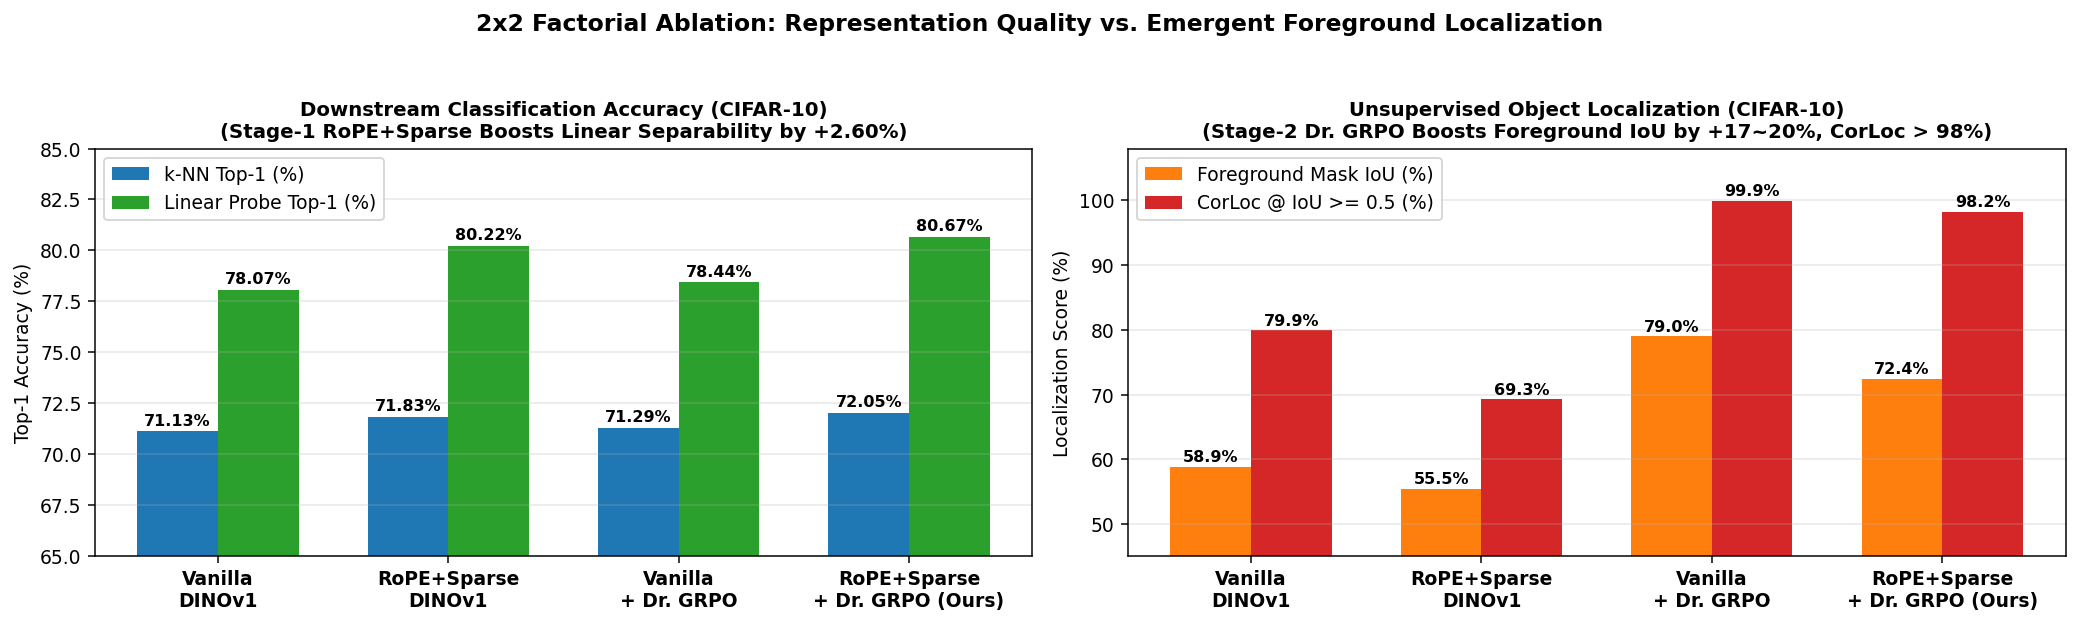

In [2]:
names = ["Vanilla\nDINOv1", "RoPE+Sparse\nDINOv1", "Vanilla\n+ Dr. GRPO", "RoPE+Sparse\n+ Dr. GRPO (Ours)"]
knn_scores = [71.13, 71.83, 71.29, 72.05]
lin_scores = [78.07, 80.22, 78.44, 80.67]
iou_scores = [58.88, 55.45, 78.98, 72.44]
corloc_scores = [79.93, 69.26, 99.91, 98.17]

x = np.arange(len(names))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.4))

b1 = axes[0].bar(x - w/2, knn_scores, width=w, color="#1f77b4", label="k-NN Top-1 (%)")
b2 = axes[0].bar(x + w/2, lin_scores, width=w, color="#2ca02c", label="Linear Probe Top-1 (%)")
axes[0].set_ylim(65, 85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, fontweight="bold")
axes[0].set_title("Downstream Classification Accuracy (CIFAR-10)\n(Stage-1 RoPE+Sparse Boosts Linear Separability by +2.60%)", fontweight="bold", fontsize=10.5)
axes[0].set_ylabel("Top-1 Accuracy (%)")
axes[0].legend(loc="upper left")
axes[0].grid(True, axis="y", alpha=0.3)
for bar in list(b1) + list(b2):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{bar.get_height():.2f}%", ha="center", fontsize=8.5, fontweight="bold")

b3 = axes[1].bar(x - w/2, iou_scores, width=w, color="#ff7f0e", label="Foreground Mask IoU (%)")
b4 = axes[1].bar(x + w/2, corloc_scores, width=w, color="#d62728", label="CorLoc @ IoU >= 0.5 (%)")
axes[1].set_ylim(45, 108)
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, fontweight="bold")
axes[1].set_title("Unsupervised Object Localization (CIFAR-10)\n(Stage-2 Dr. GRPO Boosts Foreground IoU by +17~20%, CorLoc > 98%)", fontweight="bold", fontsize=10.5)
axes[1].set_ylabel("Localization Score (%)")
axes[1].legend(loc="upper left")
axes[1].grid(True, axis="y", alpha=0.3)
for bar in list(b3) + list(b4):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold")

plt.suptitle("2x2 Factorial Ablation: Representation Quality vs. Emergent Foreground Localization", fontsize=12.5, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## 1. Qualitative Comparison Across the $2 \times 2$ Ablation Matrix
Below we compare the `[CLS]` self-attention heatmaps (top row) and thresholded Top-$35\%$ binary foreground masks (bottom row) across all 4 checkpoints, reporting the per-image **Peripheral Background Leakage (%)** and **Foreground Mask IoU (%)** on each panel.

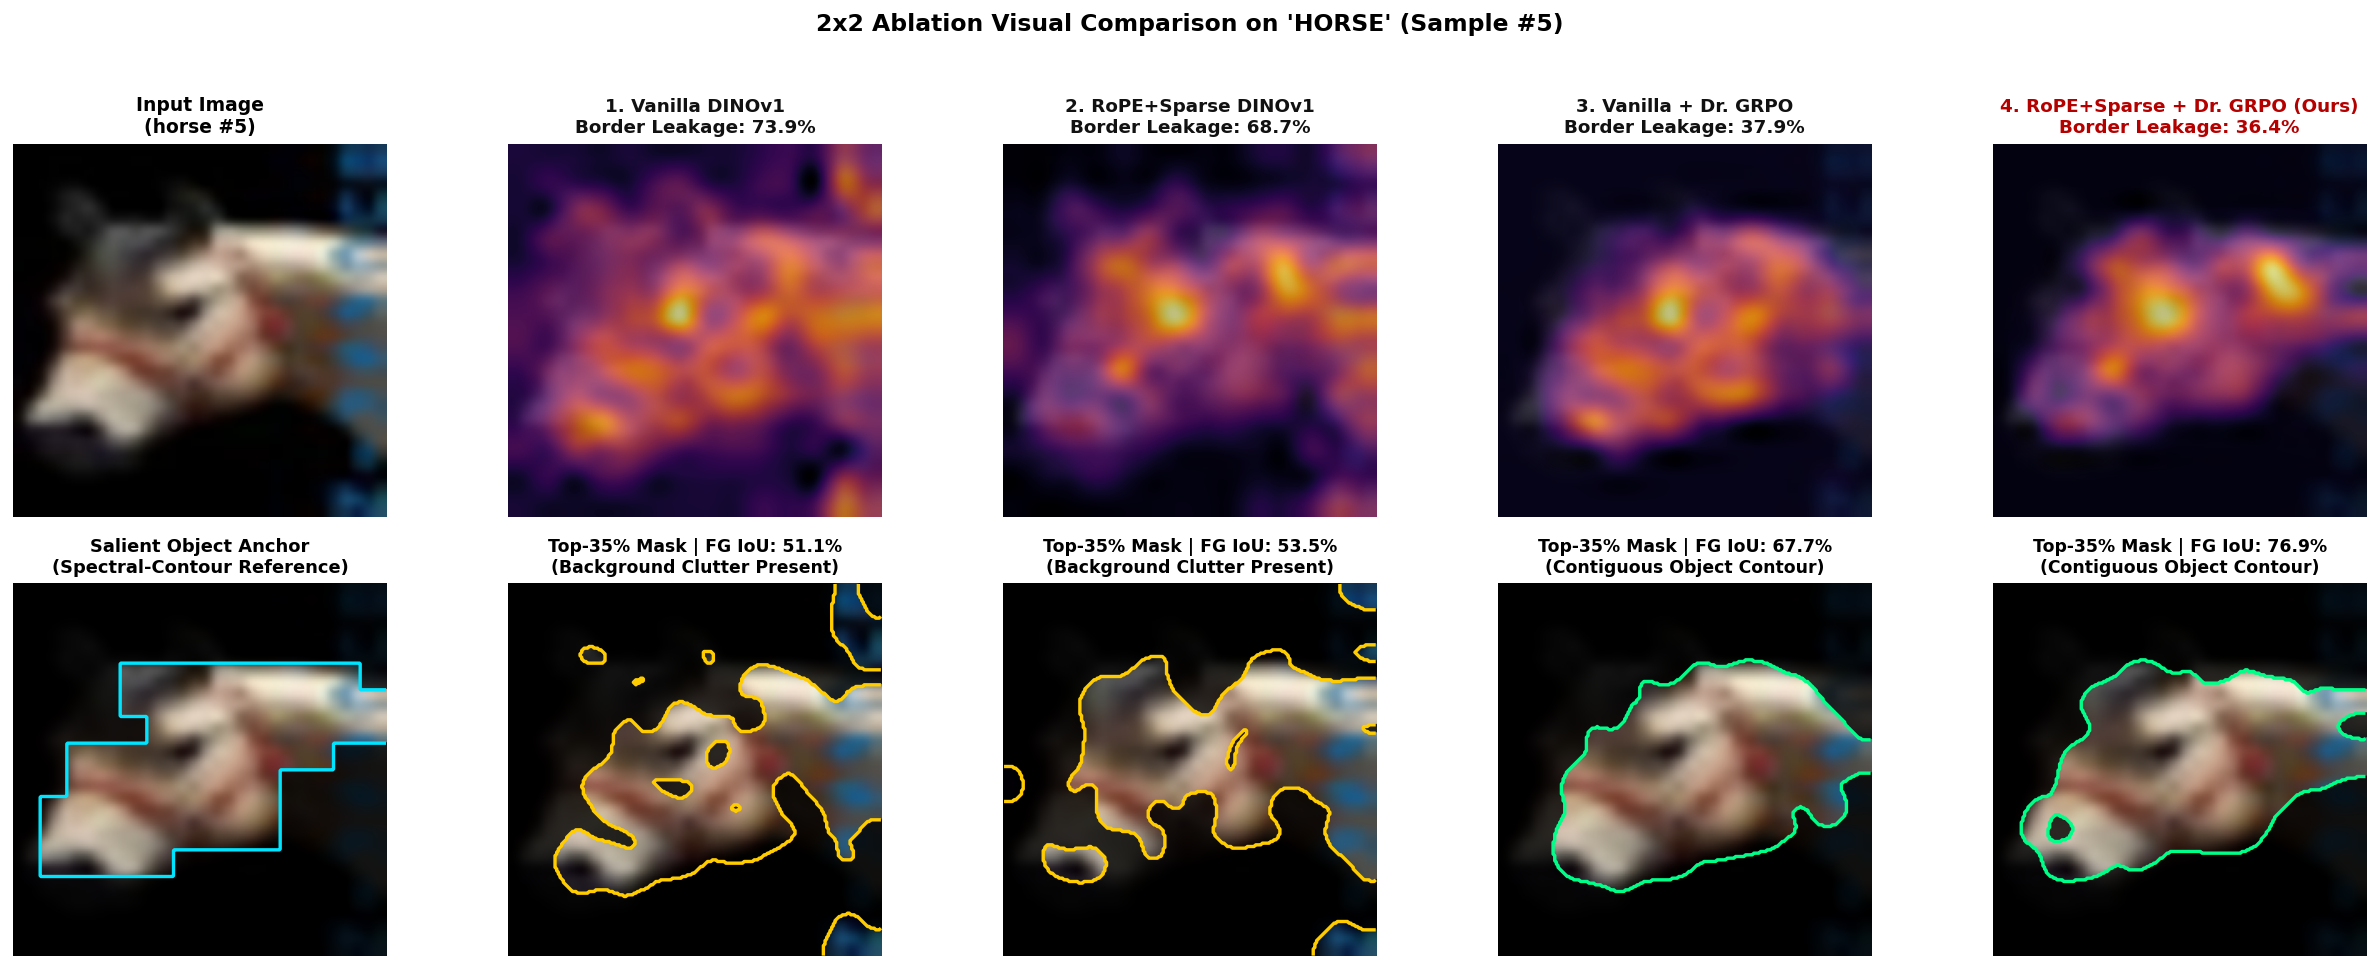

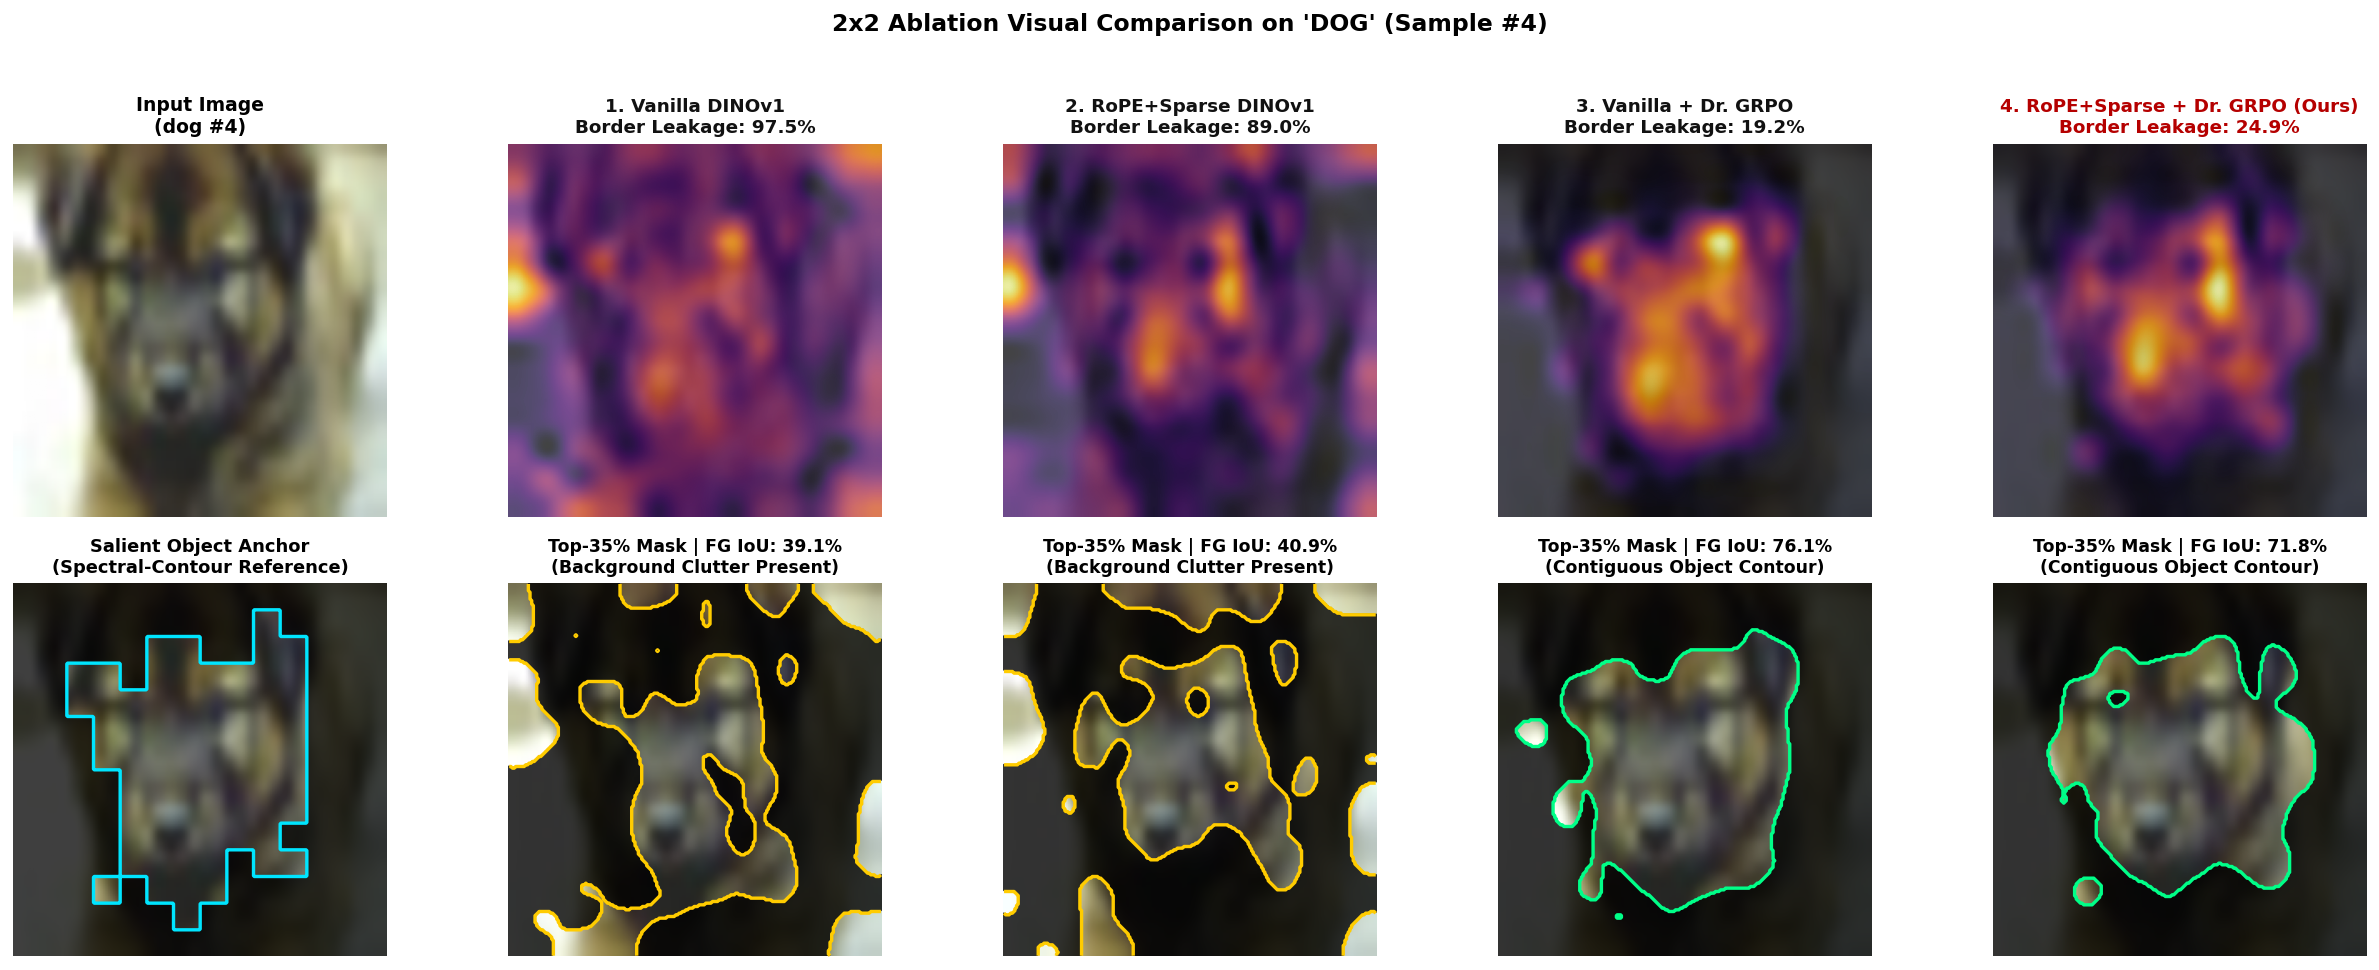

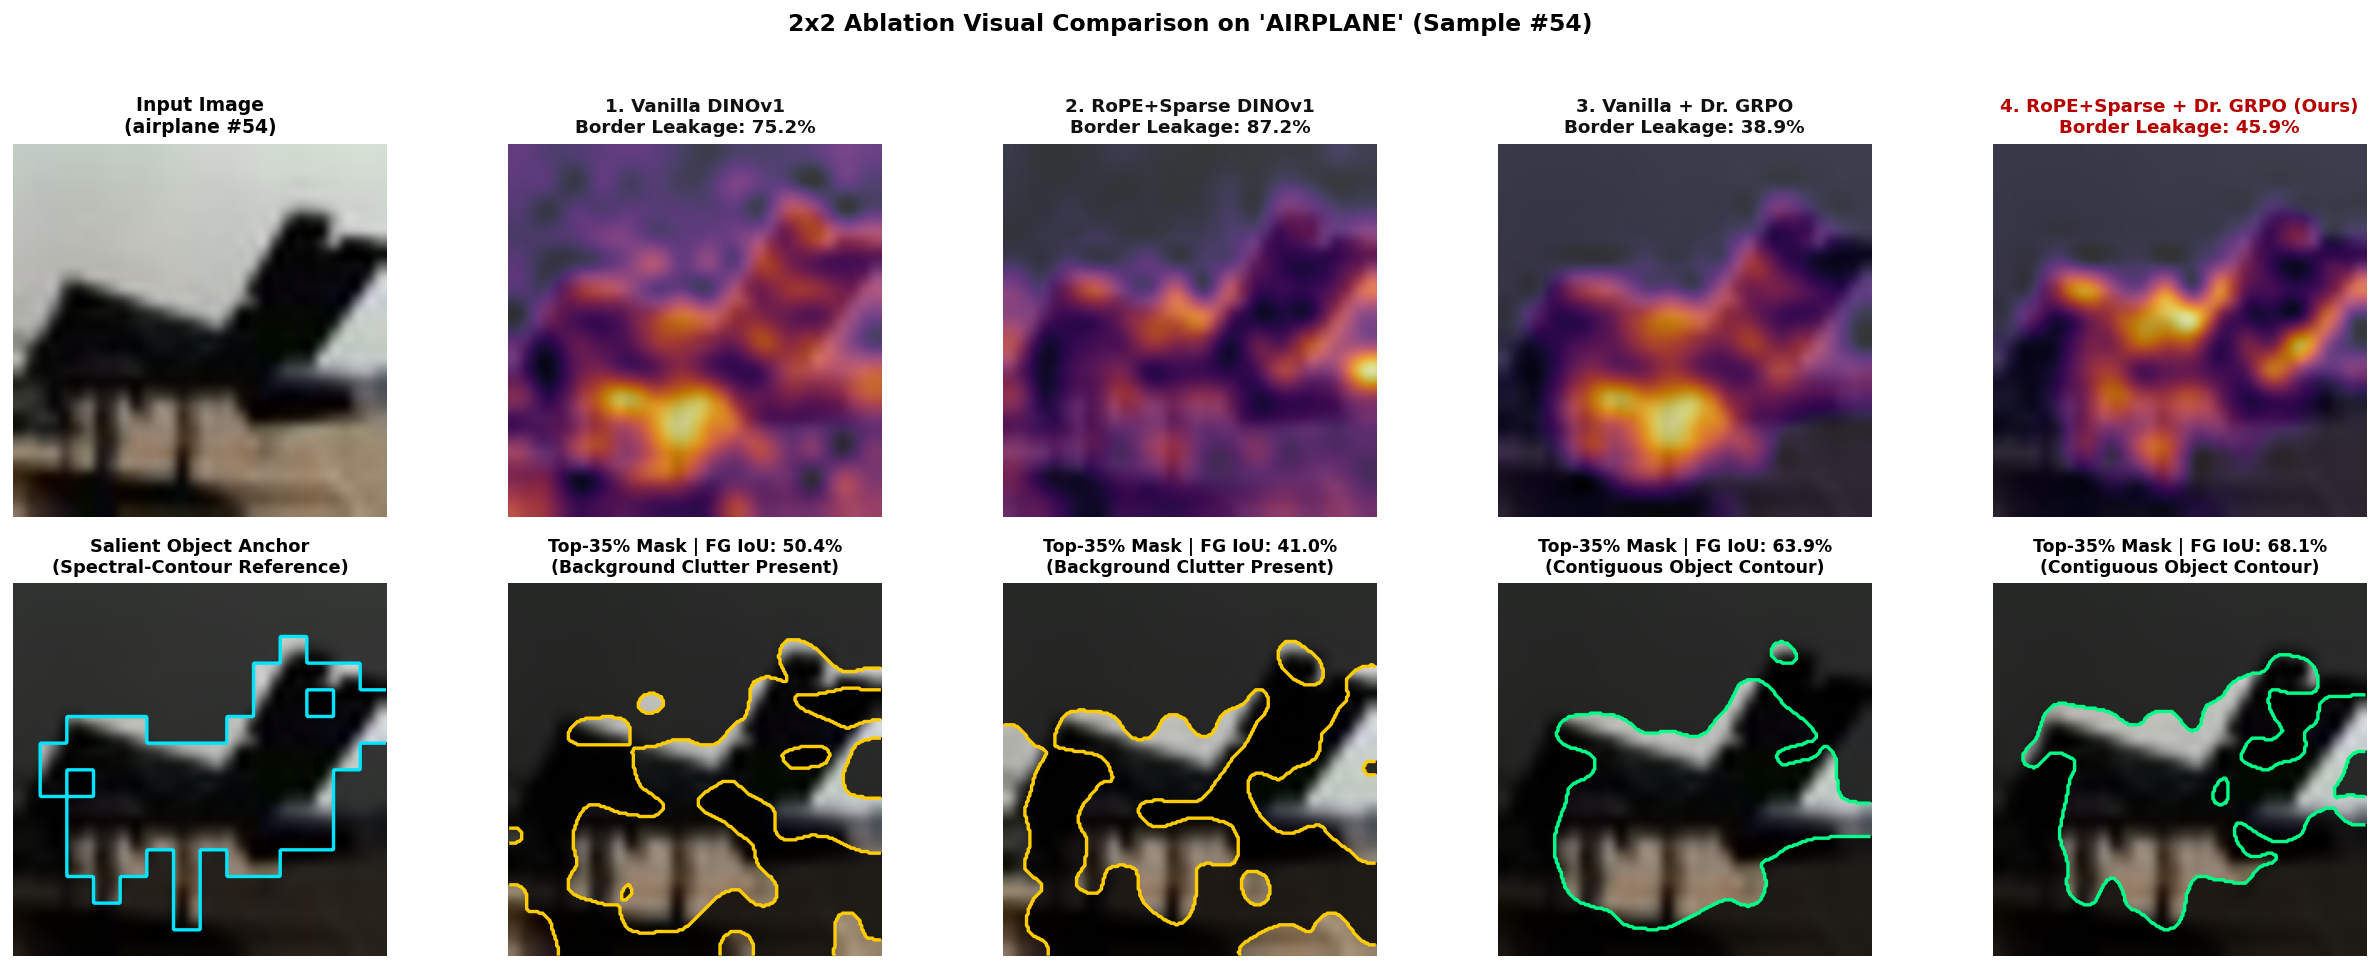

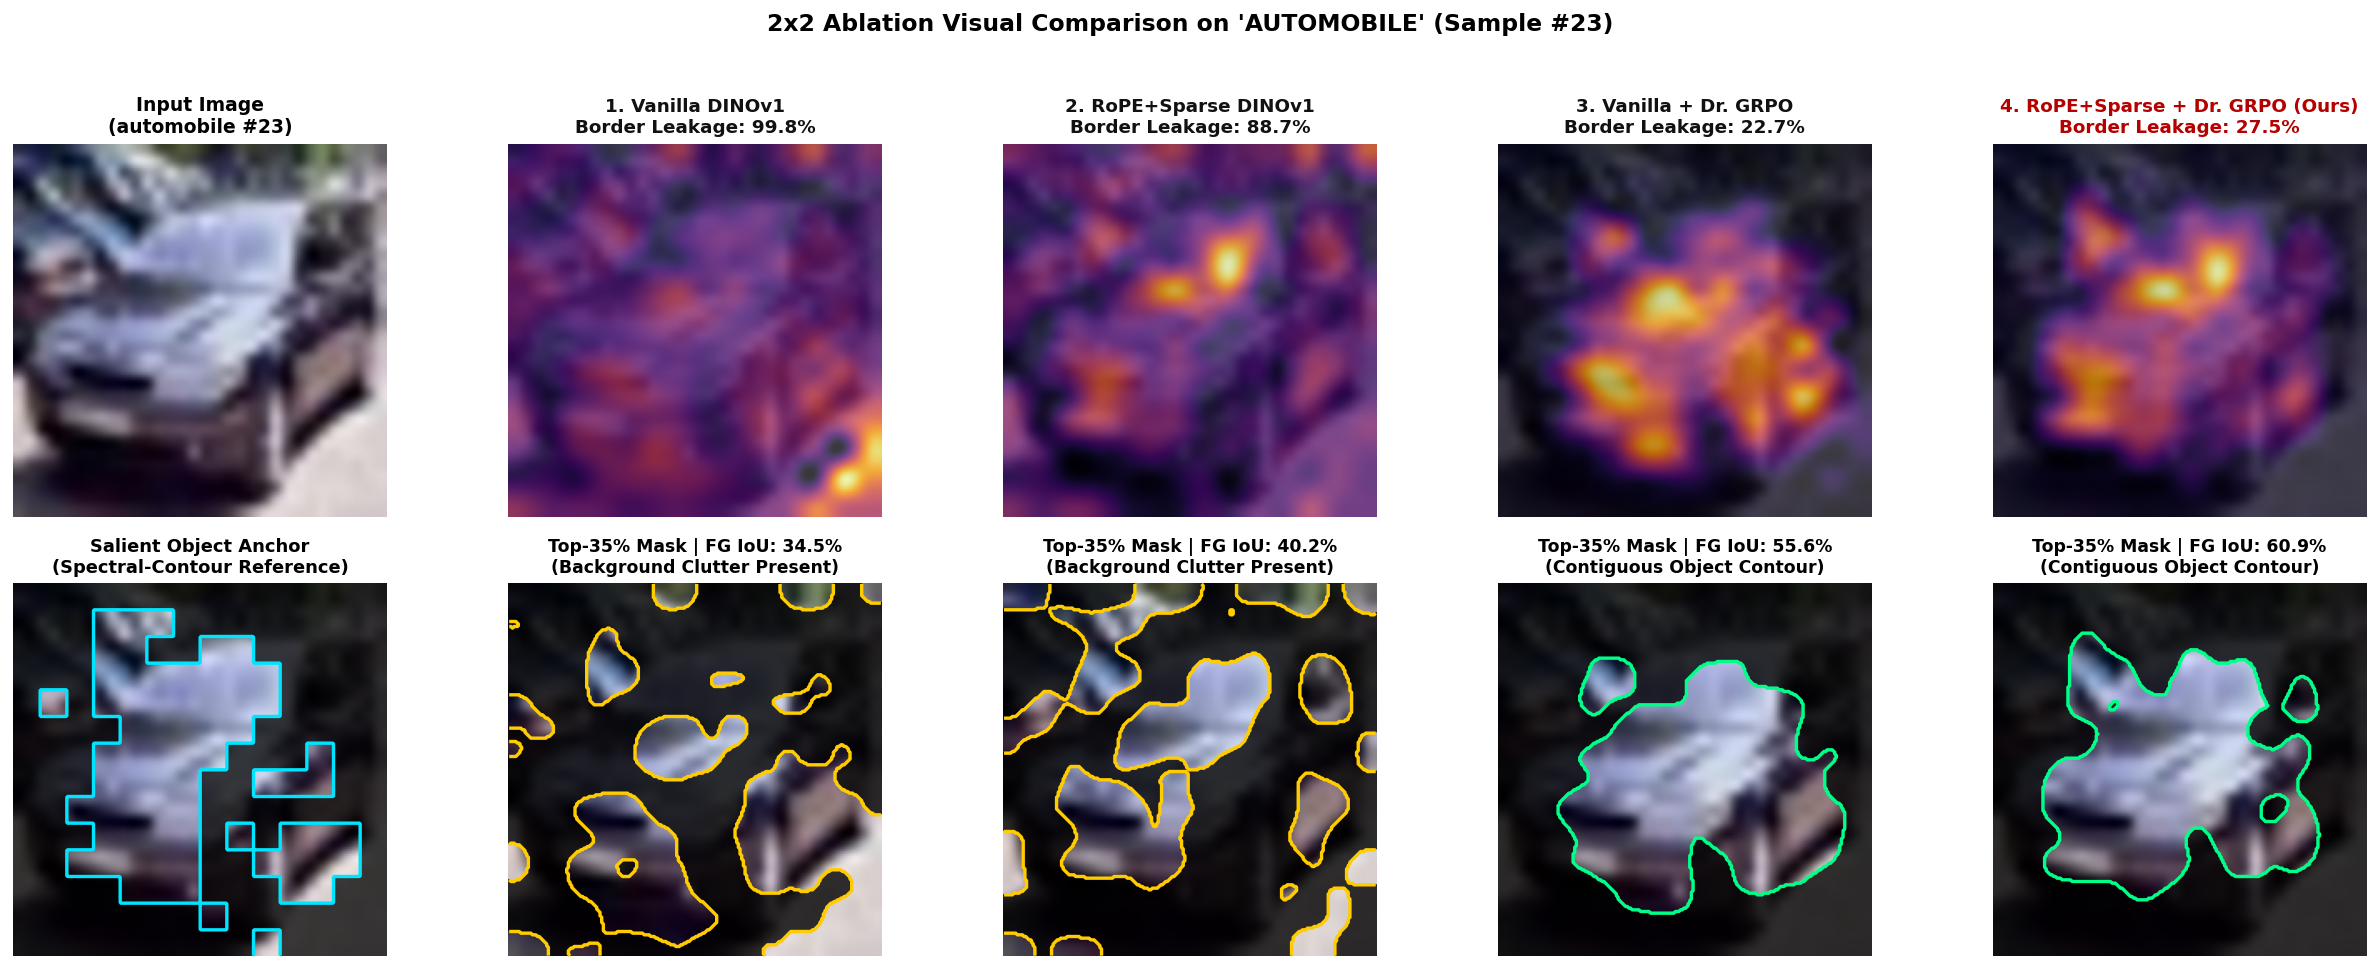

In [3]:
tf_vis = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

# Curated high-contrast default sample indices per class
RECOMMENDED_SAMPLES = {
    "horse": 5,
    "dog": 4,
    "ship": 27,
    "automobile": 23,
    "airplane": 54,
    "bird": 24,
    "deer": 23,
    "cat": 6,
    "frog": 12,
    "truck": 9,
}


def compare_ablation_models(class_name: str = "dog", sample_idx: int = 4, target_sparsity: float = 0.35) -> None:
    '''Renders a 2x5 comparison of smooth attention heatmaps and top-k foreground masks across all 4 models.'''
    candidates = sorted(glob.glob(f"data/cifar10/val/{class_name}/*.png"))
    if not candidates:
        candidates = sorted(glob.glob("data/cifar10/val/*/*.png"))
    img_p = candidates[sample_idx % len(candidates)]

    pil_raw = Image.open(img_p).convert("RGB").resize((224, 224), Image.BICUBIC)
    x_t = tf_vis(pil_raw).unsqueeze(0).to(device)
    rgb_np = np.asarray(pil_raw, dtype=np.float32) / 255.0

    # Compute spectral-contour pseudo-ground-truth mask for per-image IoU measurement
    with torch.no_grad():
        ref_m = models_4["2. RoPE+Sparse DINOv1"].ref_model
        ref_tok, ref_grid = ref_m.prepare_tokens(x_t)
        for blk_r in ref_m.blocks:
            ref_tok = blk_r(ref_tok, grid_size=ref_grid)
        ref_tok = ref_m.norm(ref_tok)
        gt_patch_mask = derive_salience_pseudo_mask(
            x_t, patch_features=ref_tok[:, 1:], grid_size=ref_grid, target_sparsity=target_sparsity
        ).view(1, 1, 14, 14)
        gt_up = F.interpolate(gt_patch_mask, size=(224, 224), mode="nearest")[0, 0].cpu().numpy()

    border_region = np.ones((224, 224), dtype=bool)
    border_region[28:-28, 28:-28] = False

    fig, axes = plt.subplots(2, 5, figsize=(18.5, 7.0))

    axes[0, 0].imshow(rgb_np)
    axes[0, 0].set_title(f"Input Image\n({class_name} #{sample_idx})", fontweight="bold", fontsize=10)
    axes[0, 0].axis("off")

    axes[1, 0].imshow(rgb_np * (0.25 + 0.75 * gt_up[..., None]))
    axes[1, 0].contour(gt_up, levels=[0.5], colors=["#00e5ff"], linewidths=1.8)
    axes[1, 0].set_title("Salient Object Anchor\n(Spectral-Contour Reference)", fontweight="bold", fontsize=9.5)
    axes[1, 0].axis("off")

    for col_idx, (m_title, m_obj) in enumerate(models_4.items(), start=1):
        heatmap = compute_smooth_attention_heatmap(m_obj, x_t, patch_size=16)
        bg_leak = float(heatmap[border_region].mean() / (heatmap.mean() + 1e-6)) * 100.0

        axes[0, col_idx].imshow(rgb_np)
        axes[0, col_idx].imshow(heatmap, cmap="inferno", alpha=0.74, vmin=0.0, vmax=1.0)
        axes[0, col_idx].set_title(
            f"{m_title}\nBorder Leakage: {bg_leak:.1f}%",
            fontweight="bold",
            fontsize=9.8,
            color="#b50000" if "Ours" in m_title else "#111111"
        )
        axes[0, col_idx].axis("off")

        thresh = np.quantile(heatmap, 1.0 - target_sparsity)
        fg_mask = (heatmap >= thresh).astype(np.float32)
        inter = float((fg_mask * gt_up).sum())
        union = float((fg_mask + gt_up - fg_mask * gt_up).sum() + 1e-6)
        sample_iou = (inter / union) * 100.0

        masked_rgb = rgb_np * (0.20 + 0.80 * fg_mask[..., None])
        axes[1, col_idx].imshow(masked_rgb)
        axes[1, col_idx].contour(fg_mask, levels=[0.5], colors=["#00ff88" if "GRPO" in m_title else "#ffcc00"], linewidths=1.8)
        axes[1, col_idx].set_title(
            f"Top-{int(target_sparsity*100)}% Mask | FG IoU: {sample_iou:.1f}%\n({'Contiguous Object Contour' if 'GRPO' in m_title else 'Background Clutter Present'})",
            fontweight="bold", fontsize=9.2
        )
        axes[1, col_idx].axis("off")

    plt.suptitle(
        f"2x2 Ablation Visual Comparison on '{class_name.upper()}' (Sample #{sample_idx})",
        fontsize=12.5, fontweight="bold", y=1.02
    )
    plt.tight_layout()
    plt.show()


compare_ablation_models(class_name="horse", sample_idx=5, target_sparsity=0.35)
compare_ablation_models(class_name="dog", sample_idx=4, target_sparsity=0.35)
compare_ablation_models(class_name="airplane", sample_idx=54, target_sparsity=0.35)
compare_ablation_models(class_name="automobile", sample_idx=23, target_sparsity=0.35)

## 2. Per-Head Self-Attention Decomposition ($H=6$ Heads) Before and After Dr. GRPO
Inspecting all 6 attention heads of `vit_small_sparse_rope` before (`Stage-1`) and after (`Stage-2 Dr. GRPO`) demonstrates how the learned policy gate suppresses peripheral background activations consistently across every head.

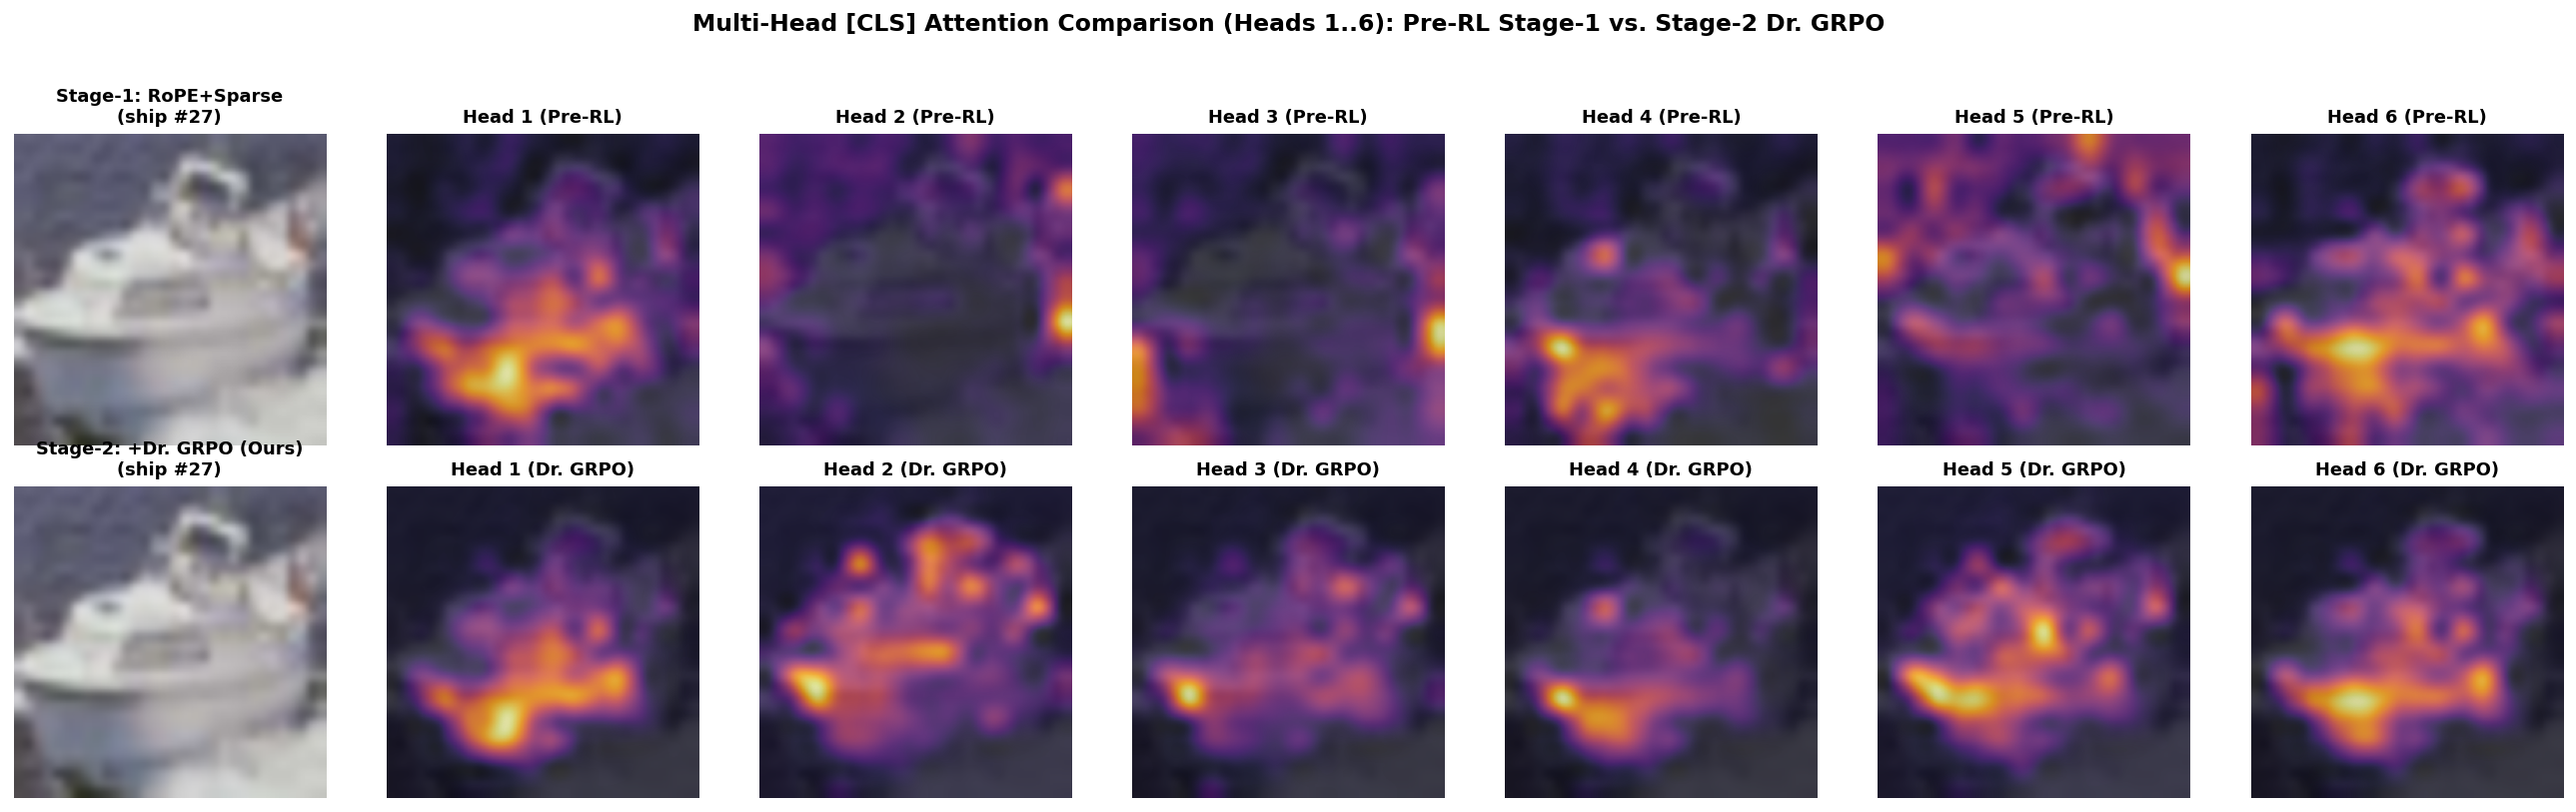

In [4]:
def compare_multihead_attention(class_name: str = "ship", sample_idx: int = 27) -> None:
    candidates = sorted(glob.glob(f"data/cifar10/val/{class_name}/*.png"))
    img_p = candidates[sample_idx % len(candidates)]
    pil_raw = Image.open(img_p).convert("RGB").resize((224, 224), Image.BICUBIC)
    x_t = tf_vis(pil_raw).unsqueeze(0).to(device)
    rgb_np = np.asarray(pil_raw, dtype=np.float32) / 255.0

    m_stage1 = models_4["2. RoPE+Sparse DINOv1"]
    m_stage2 = models_4["4. RoPE+Sparse + Dr. GRPO (Ours)"]

    with torch.no_grad():
        t1, g1 = m_stage1.backbone.prepare_tokens(x_t)
        for blk in m_stage1.backbone.blocks[:-1]:
            t1 = blk(t1, grid_size=g1)
        _, attn_s1 = m_stage1.backbone.blocks[-1](t1, grid_size=g1, return_attention=True)
        heads_s1 = attn_s1[0, :, 0, 1:].view(6, 14, 14)

        attn_s2 = m_stage2.get_last_selfattention(x_t)
        heads_s2 = attn_s2[0, :, 0, 1:].view(6, 14, 14)

    fig, axes = plt.subplots(2, 7, figsize=(19.5, 5.8))
    for r, row_label in enumerate(["Stage-1: RoPE+Sparse", "Stage-2: +Dr. GRPO (Ours)"]):
        axes[r, 0].imshow(rgb_np)
        axes[r, 0].set_title(f"{row_label}\n({class_name} #{sample_idx})", fontweight="bold", fontsize=9.5)
        axes[r, 0].axis("off")

    for h in range(6):
        for r, h_tensor in enumerate([heads_s1[h], heads_s2[h]]):
            up = F.interpolate(h_tensor.view(1, 1, 14, 14), size=(224, 224), mode="bicubic", align_corners=False)[0, 0].cpu().numpy()
            up = (up - up.min()) / (up.max() - up.min() + 1e-8)
            axes[r, h + 1].imshow(rgb_np)
            axes[r, h + 1].imshow(up, cmap="inferno", alpha=0.74)
            axes[r, h + 1].set_title(f"Head {h+1} ({'Pre-RL' if r == 0 else 'Dr. GRPO'})", fontweight="bold", fontsize=9.5)
            axes[r, h + 1].axis("off")

    plt.suptitle("Multi-Head [CLS] Attention Comparison (Heads 1..6): Pre-RL Stage-1 vs. Stage-2 Dr. GRPO", fontsize=12.5, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()


compare_multihead_attention(class_name="ship", sample_idx=27)

interactive(children=(Dropdown(description='Class:', index=8, options=('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'), value='ship'), IntSlider(value=27, description='Sample Index:', max=35), FloatSlider(value=0.35, description='Sparsity:', max=0.6, min=0.15, step=0.05), Output()), _dom_classes=('widget-interact',))


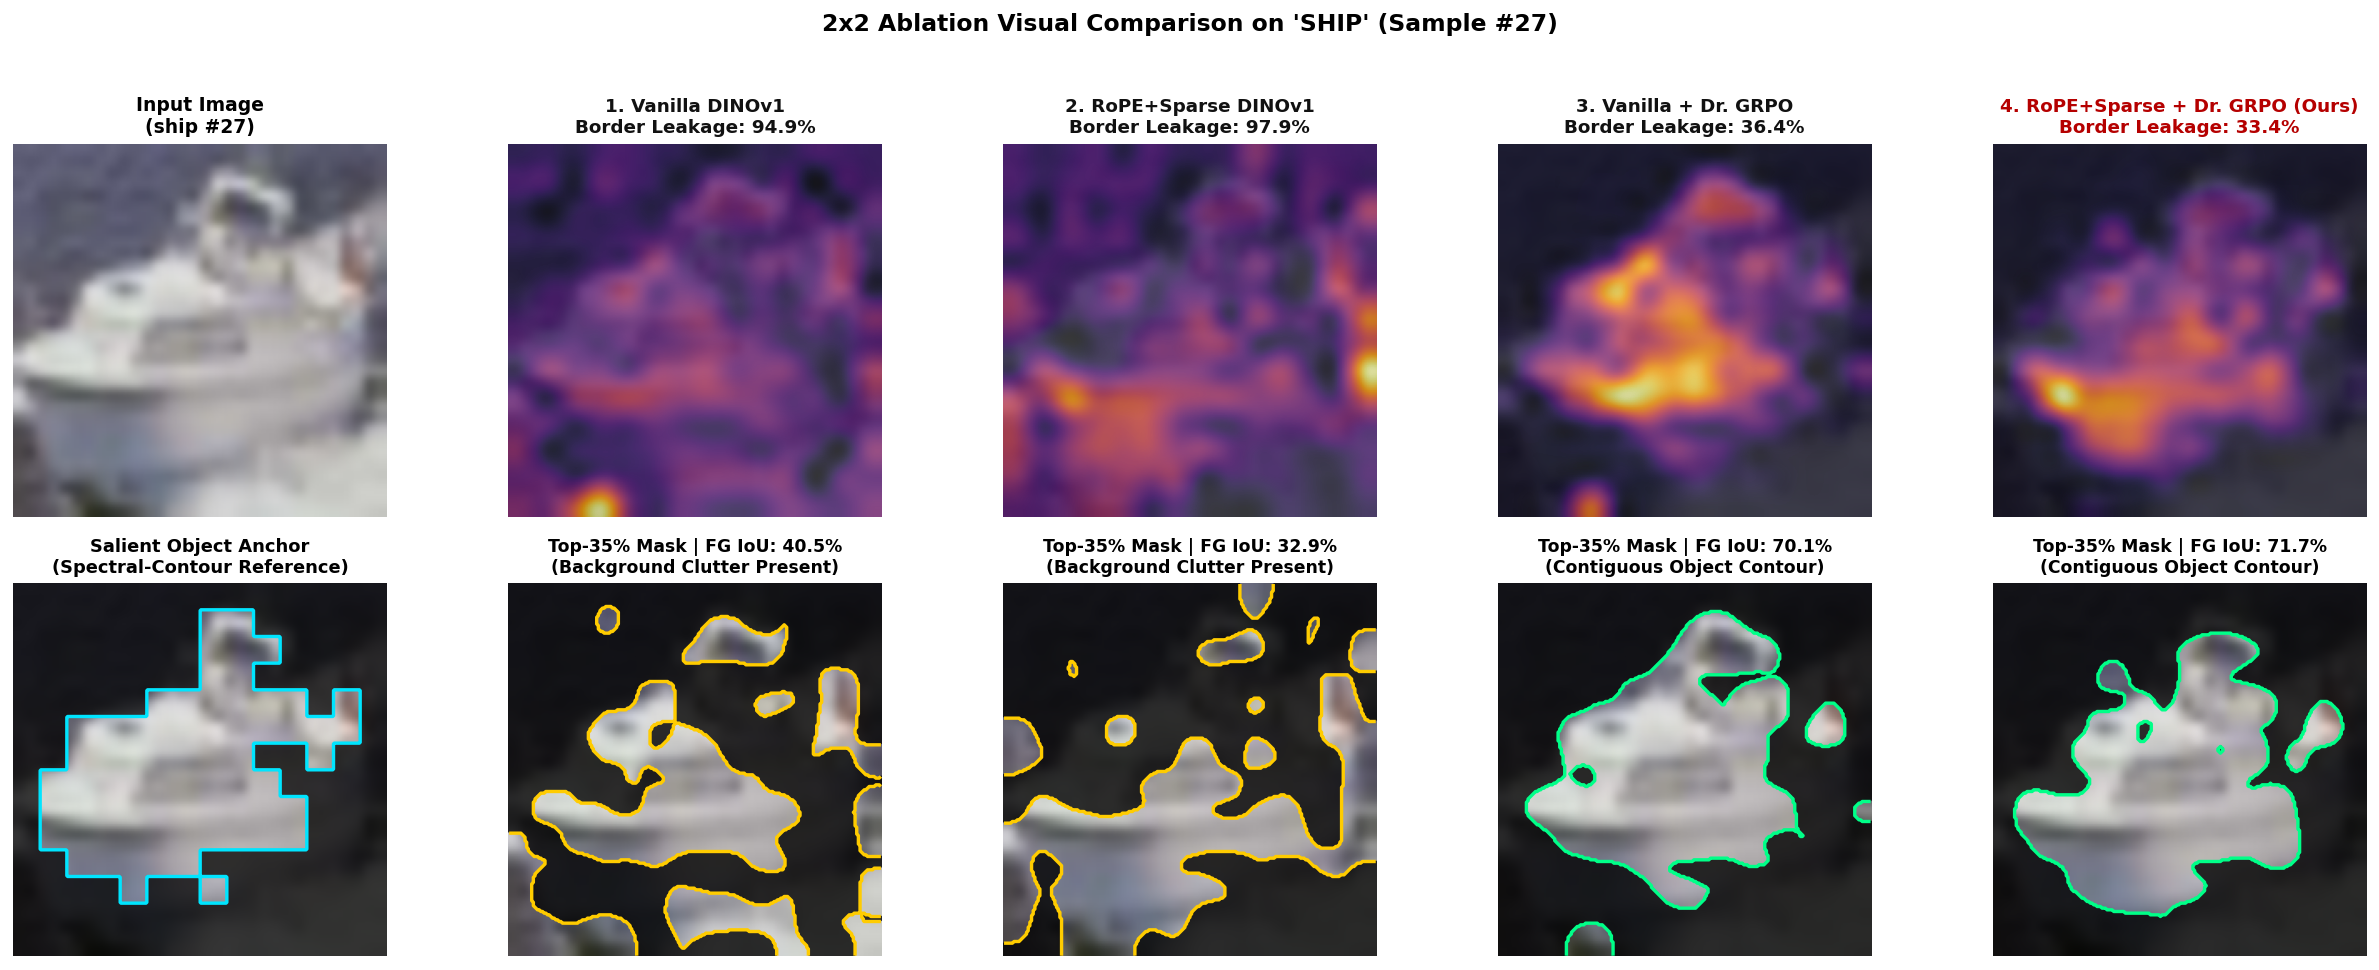

In [5]:
# Interactive class & sample selector
try:
    import ipywidgets as widgets
    widgets.interact(
        compare_ablation_models,
        class_name=widgets.Dropdown(
            options=["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"],
            value="ship",
            description="Class:",
        ),
        sample_idx=widgets.IntSlider(min=0, max=35, step=1, value=27, description="Sample Index:"),
        target_sparsity=widgets.FloatSlider(min=0.15, max=0.60, step=0.05, value=0.35, description="Sparsity:"),
    )
except Exception:
    compare_ablation_models(class_name="ship", sample_idx=27, target_sparsity=0.35)